<a href="https://colab.research.google.com/github/yashwand/24ai112---Yashwand-/blob/main/CAT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%bash
pip install python-docx -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 1.9 MB/s eta 0:00:00


In [2]:
import docx
import scipy.io
import numpy as np
import pandas as pd

# Read DOCX metadata/description if any
try:
    doc = docx.Document('/content/Traffic Flow Prediction Dataset.docx')
    fullText = []
    for para in doc.paragraphs:
        fullText.append(para.text)
    print("--- DOCX Content Summary ---")
    print('\n'.join(fullText[:30]))  # Print first 30 lines
except Exception as e:
    print(f"Could not read DOCX: {e}")

# Read MAT file keys
try:
    mat = scipy.io.loadmat('/content/traffic_dataset.mat')
    print("\n--- MAT File Keys ---")
    print([k for k in mat.keys() if not k.startswith('__')])
except Exception as e:
    print(f"Could not read MAT file: {e}")

--- DOCX Content Summary ---
Traffic Flow Prediction Dataset

Introduction
The goal for this dataset is to forecast the spatio-temporal traffic volume based on the historical traffic volume and other features in neighboring locations. Specifically, the traffic volume is measured every 15 minutes at 36 sensor locations along two major highways in Northern Virginia/Washington D.C. capital region. The 47 features include: 1) the historical sequence of traffic volume sensed during the 10 most recent sample points (10 features), 2) week day (7 features), 3) hour of day (24 features), 4) road direction (4 features), 5) number of lanes (1 feature), and 6) name of the road (1 feature). The goal is to predict the traffic volume 15 minutes into the future for all sensor locations. With a given road network, we know the spatial connectivity between sensor locations.

Processed Data
Download link: [Dataset]

Data format: *.mat (use Matlab to open)

Data description:

Citation
To use these datasets

In [3]:
import scipy.io
import numpy as np

mat_data = scipy.io.loadmat('/content/traffic_dataset.mat')

for key in ['tra_X_tr', 'tra_X_te', 'tra_Y_tr', 'tra_Y_te']:
    val = mat_data[key]
    print(f"{key}: type={type(val)}, shape={val.shape}")
    if isinstance(val, np.ndarray) and val.dtype == object:
        print(f"  Inner element shape: {val[0,0].shape if val.size > 0 else 'empty'}, type: {type(val[0,0]) if val.size > 0 else 'None'}")

tra_X_tr: type=<class 'numpy.ndarray'>, shape=(1, 1261)
  Inner element shape: (36, 48), type: <class 'scipy.sparse._csc.csc_array'>
tra_X_te: type=<class 'numpy.ndarray'>, shape=(1, 840)
  Inner element shape: (36, 48), type: <class 'scipy.sparse._csc.csc_array'>
tra_Y_tr: type=<class 'numpy.ndarray'>, shape=(36, 1261)
tra_Y_te: type=<class 'numpy.ndarray'>, shape=(36, 840)


In [4]:
import scipy.io
import numpy as np

# Load the dataset
mat_data = scipy.io.loadmat('/content/traffic_dataset.mat')

# Inspect the structures of the data splits
for key in ['tra_X_tr', 'tra_X_te', 'tra_Y_tr', 'tra_Y_te']:
    val = mat_data[key]
    print(f"{key}: type={type(val)}, shape={val.shape}")
    # If it is nested as array of arrays, let's look at the inner elements
    if isinstance(val, np.ndarray) and val.dtype == object:
        print(f"  Inner element type: {type(val[0,0])}, shape/info: {val[0,0]}")

tra_X_tr: type=<class 'numpy.ndarray'>, shape=(1, 1261)
  Inner element type: <class 'scipy.sparse._csc.csc_array'>, shape/info: <Compressed Sparse Column sparse array of dtype 'float64'
	with 540 stored elements and shape (36, 48)>
  Coords	Values
  (0, 0)	0.09248014946286783
  (1, 0)	0.09715086408220458
  (2, 0)	0.11536665109761794
  (3, 0)	0.1120971508640822
  (4, 0)	0.12704343764595982
  (5, 0)	0.12517515179822514
  (6, 0)	0.14432508173750583
  (7, 0)	0.09855207846800561
  (8, 0)	0.14946286781877627
  (9, 0)	0.18262494161606727
  (10, 0)	0.14385801027557216
  (11, 0)	0.15973843998131715
  (12, 0)	0.16814572629612332
  (13, 0)	0.15366651097617937
  (14, 0)	0.19570294255021017
  (15, 0)	0.09528257823446988
  (16, 0)	0.1742176553012611
  (17, 0)	0.23353573096683794
  (18, 0)	0.1938346567024755
  (19, 0)	0.2606258757589911
  (20, 0)	0.2554880896777207
  (21, 0)	0.2727697337692667
  (22, 0)	0.067725361980383
  (23, 0)	0.05558150397010743
  (24, 0)	0.031293787949556284
  :	:
  (22, 44)	1

In [5]:
import numpy as np
import scipy.io
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import matplotlib.pyplot as plt

# Load raw data
mat_data = scipy.io.loadmat('/content/traffic_dataset.mat')
tra_X_tr = mat_data['tra_X_tr']
tra_X_te = mat_data['tra_X_te']
tra_Y_tr = mat_data['tra_Y_tr']
tra_Y_te = mat_data['tra_Y_te']

num_sensors = 36
num_features = 48

# Function to unpack nested structures to standard numpy arrays
def unpack_data(X_nested, Y_dense):
    num_samples = X_nested.shape[1]

    # We will build flat datasets: each sample is a (sensor, feature_vector) pair
    X_flat = []
    Y_flat = []

    for t in range(num_samples):
        # Get the 36x48 sparse array and convert to dense numpy
        grid = X_nested[0, t].toarray()
        for sensor in range(num_sensors):
            X_flat.append(grid[sensor])
            Y_flat.append(Y_dense[sensor, t])

    return np.array(X_flat), np.array(Y_flat)

print("Unpacking training and testing datasets...")
X_train, y_train = unpack_data(tra_X_tr, tra_Y_tr)
X_test, y_test = unpack_data(tra_X_te, tra_Y_te)

print(f"Training set shape: X={X_train.shape}, y={y_train.shape}")
print(f"Testing set shape: X={X_test.shape}, y={y_test.shape}")

Unpacking training and testing datasets...
Training set shape: X=(45396, 48), y=(45396,)
Testing set shape: X=(30240, 48), y=(30240,)


In [6]:
# Train a Random Forest model
print("Training Random Forest Regressor...")
model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Predict and Evaluate
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = root_mean_squared_error(y_test, predictions)

print(f"Evaluation Metrics on Test Set:")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

Training Random Forest Regressor...
Evaluation Metrics on Test Set:
Mean Absolute Error (MAE): 0.0253
Root Mean Squared Error (RMSE): 0.0382


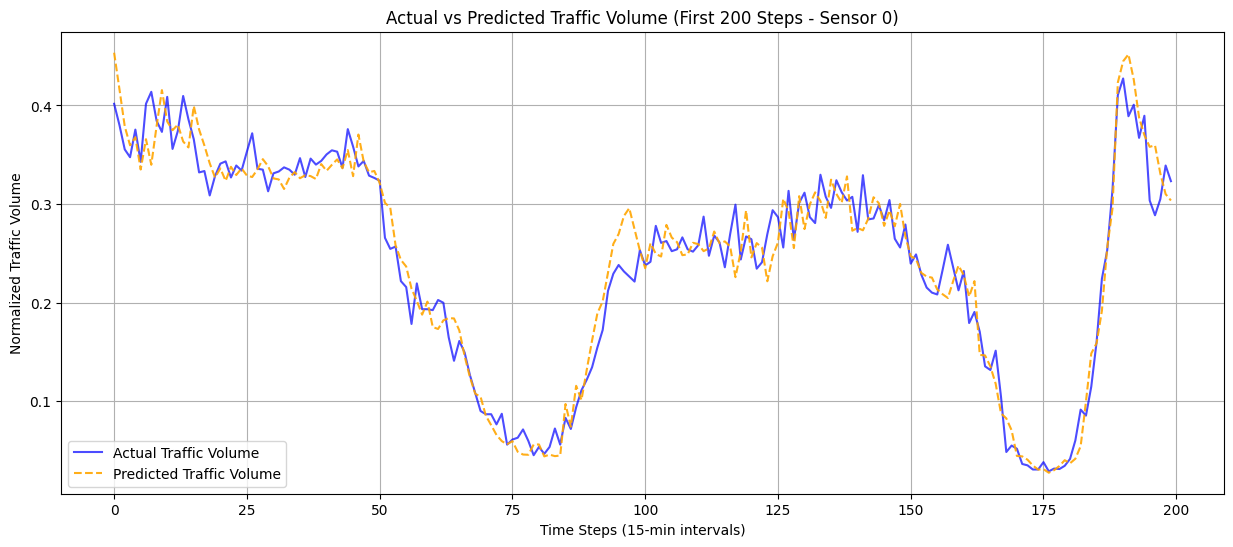

In [7]:
# Plot actual vs predicted traffic volume for a sample sensor over time
# Re-arrange back to (sensors, time_steps) for plotting convenience
y_test_reshaped = y_test.reshape(840, 36).T
predictions_reshaped = predictions.reshape(840, 36).T

# Let's select Sensor 0
sensor_idx = 0
plt.figure(figsize=(15, 6))
plt.plot(y_test_reshaped[sensor_idx, :200], label='Actual Traffic Volume', color='blue', alpha=0.7)
plt.plot(predictions_reshaped[sensor_idx, :200], label='Predicted Traffic Volume', color='orange', linestyle='--', alpha=0.9)
plt.title(f'Actual vs Predicted Traffic Volume (First 200 Steps - Sensor {sensor_idx})')
plt.xlabel('Time Steps (15-min intervals)')
plt.ylabel('Normalized Traffic Volume')
plt.legend()
plt.grid(True)
plt.show()